# Sustento del proyecto: gráficos y comprobaciones

**Minería de contrataciones públicas del Perú (OECE, OCDS 2023–2025)** · Rodo Vilcarromero · Ronaldo Flores · Isaac Vera

Este cuaderno respalda cada afirmación del reporte web con un gráfico y una comprobación automática. No vuelve a correr
Spark: lee los artefactos que exporta el pipeline (`artifacts/`), los mismos que muestra la web.

Cada sección tiene la misma estructura:

1. **Qué se afirma.**
2. **Gráfico** con los datos de la corrida completa.
3. **Comprobación**: un control que compara el resultado con la teoría, con la versión exacta o con un invariante
   (✔ se cumple · ✘ no se cumple). Al final hay una tabla con todos los controles.

Fuente de datos: [Registro OCDS, publicación 135 (OECE)](https://data.open-contracting.org/es/publication/135),
licencia CC BY 4.0.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ART = next(p for p in [Path('../artifacts'), Path('artifacts'), Path('/artifacts')] if p.is_dir())
plt.rcParams.update({'figure.figsize': (10, 4.2), 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
TEAL, ORANGE, NAVY, BROWN = '#167c80', '#de7c45', '#384b72', '#93785e'
pd.set_option('display.max_colwidth', 80)


def csv(name):
    return pd.read_csv(ART / name)


def doc(name):
    return json.loads((ART / name).read_text(encoding='utf-8'))


CHECKS = []


def check(part, claim, ok, detail=''):
    CHECKS.append(dict(parte=part, comprobación=claim, resultado='✔' if ok else '✘', detalle=detail))
    print(f"{'✔' if ok else '✘'} {claim}" + (f' — {detail}' if detail else ''))


manifest = doc('metadata/run_manifest.json')
print('Corrida:', manifest['profile'], '· código', manifest['code_version'], '·', manifest['finished_at'][:19])

Corrida: completo · código 07ad5f6 · 2026-10-11T21:41:35


## 1. Datos y KDD

**Qué se afirma.** De 279 105 registros OCDS se analizan 196 277 procesos convocados en 2023–2025 (la versión más
reciente de cada `ocid`). Los montos se convierten a soles con trazabilidad y no se pierden ni duplican al repartirlos
entre proveedores.

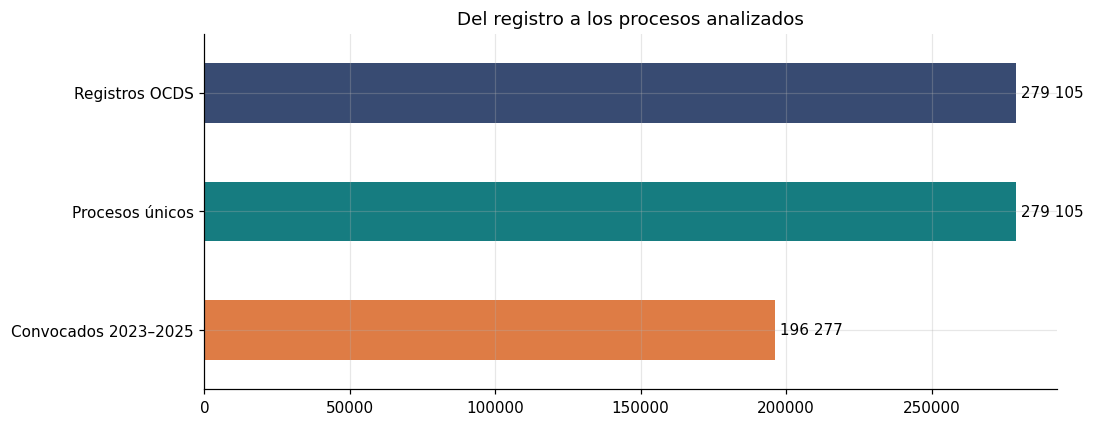

,filas
processes,196277
items,230496
awards,164712
suppliers,161255
contracts,159703
tenderers,2286969


✔ Cada ocid aparece una sola vez
✔ El monto repartido entre proveedores conserva el total adjudicado
✔ Los totales del EDA coinciden con la tabla de procesos
✔ Ningún monto negativo entra al análisis


In [2]:
q = doc('metadata/quality_summary.json')
funnel = pd.Series({'Registros OCDS': q['raw_records'],
                    'Procesos únicos': q['raw_records'] - q['duplicate_ocids'] - q['missing_ocid'],
                    'Convocados 2023–2025': q['selected_processes']})
ax = funnel.plot.barh(color=[NAVY, TEAL, ORANGE]); ax.invert_yaxis(); ax.set_title('Del registro a los procesos analizados')
for i, v in enumerate(funnel): ax.text(v, i, f' {v:,}'.replace(',', ' '), va='center')
plt.show()
display(pd.DataFrame(q['table_counts'], index=['filas']).T)

validation = doc('metadata/artifact_validation.json')['checks']
check('Datos', 'Cada ocid aparece una sola vez', validation['unique_ocid'])
check('Datos', 'El monto repartido entre proveedores conserva el total adjudicado',
      validation['supplier_allocation_conserves_amount'])
check('Datos', 'Los totales del EDA coinciden con la tabla de procesos',
      validation['eda_conservation_tender_amount_pen'] and validation['eda_conservation_award_amount_pen'])
check('Datos', 'Ningún monto negativo entra al análisis', q['negative_amounts'] == 0)

## 2. EDA en Spark

**Qué se afirma.** La serie mensual muestra el ciclo presupuestal (pico de fin de año) y la transición a la Ley 32069 en
2025; los montos tienen una cola muy larga (pocos procesos concentran casi todo el valor).

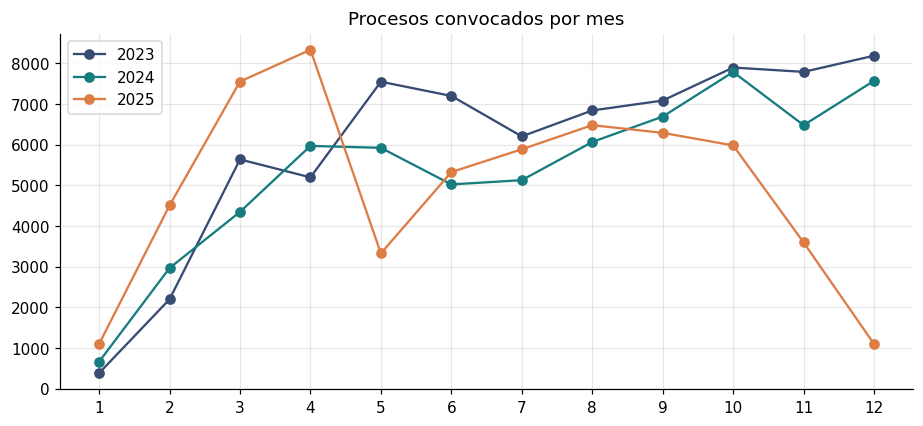

,year,category,processes,mean,p50,p90,p99
0,2023,goods,34584,563146.0,120400.0,705859.0,6953038.0
1,2023,services,30970,874134.0,140000.0,836395.0,9410634.0
2,2023,works,6624,5822766.0,1239007.0,8953083.0,73656458.0
3,2024,goods,29424,461502.0,104100.0,646846.0,6138153.0
4,2024,services,28498,701282.0,140000.0,763206.0,9205247.0
5,2024,works,6697,8610512.0,1352620.0,10106370.0,182792451.0
6,2025,goods,27032,397093.0,117483.0,566756.0,3951459.0
7,2025,services,25751,623085.0,134559.0,708919.0,8567774.0
8,2025,works,6697,6125158.0,911083.0,9119882.0,85112808.0


✔ En cada año y categoría la media supera a la mediana (cola larga a la derecha)


In [3]:
monthly = csv('eda/monthly_evolution.csv').sort_values(['year', 'month'])
fig, ax = plt.subplots()
for (year, g), color in zip(monthly.groupby('year'), [NAVY, TEAL, ORANGE]):
    ax.plot(g.month, g.processes, marker='o', color=color, label=year)
ax.set_xticks(range(1, 13)); ax.set_title('Procesos convocados por mes'); ax.legend(); plt.show()

pct = csv('eda/amount_percentiles.csv')
display(pct[['year', 'category', 'processes', 'mean', 'p50', 'p90', 'p99']].round(0))
check('EDA', 'En cada año y categoría la media supera a la mediana (cola larga a la derecha)',
      bool((pct['mean'] > pct['p50']).all()))

### 2.1 Frecuencia de los ítems

**Qué se afirma.** Cada ítem trae un código del catálogo CUBSO; sus dos primeros dígitos son el segmento UNSPSC. Se
cuenta qué se pide con más frecuencia y qué concentra el dinero.

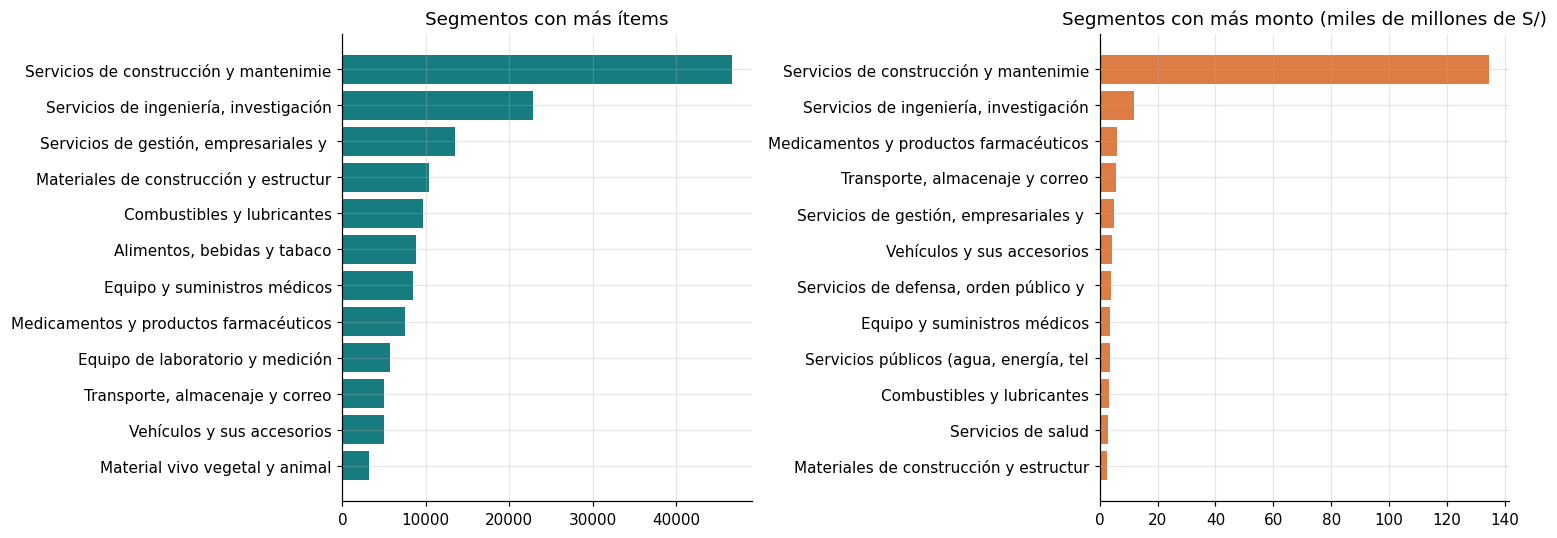

,classification,description,segment_name,items,processes
0,1510150500233280,DIESEL B5 S-50,Combustibles y lubricantes,6316,5784
1,7214100300230730,SERVICIO DE MANTENIMIENTO RUTINARIO DE CAMINOS,Servicios de construcción y mantenimiento,4763,4500
2,8010150500228925,SERVICIO DE SEGUIMIENTO Y MONITOREO DE ACTIVIDADES DE CAMPO,"Servicios de gestión, empresariales y administrativos",2961,2950
3,5013170200307453,LECHE EVAPORADA ENTERA X 400 g APROX.,"Alimentos, bebidas y tabaco",2164,2099
4,9210150100094854,SERVICIO DE SEGURIDAD Y VIGILANCIA,"Servicios de defensa, orden público y seguridad",2074,1587
5,3011160100012953,CEMENTO PORTLAND PUZOLANICO TIPO IP X 42.50 kg,Materiales de construcción y estructuras,1995,1985
6,3011160100012771,CEMENTO PORTLAND TIPO I X 42.50 kg,Materiales de construcción y estructuras,1928,1863
7,7212140300341204,SERVICIO DE MANTENIMIENTO DE INFRAESTRUCTURA DE CENTROS DE SALUD,Servicios de construcción y mantenimiento,1488,1345
8,8013150200094959,SERVICIO DE ALQUILER DE INMUEBLE,"Servicios de gestión, empresariales y administrativos",1396,1368
9,7214100100233103,CONSTRUCCION DE CALLES CON PAVIMENTO,Servicios de construcción y mantenimiento,1387,1369


✔ Los ítems por segmento suman los ítems con código — 194 202 ítems


In [4]:
segments = csv('eda/item_segments.csv')
items_summary = doc('eda/item_summary.json')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top = segments.head(12).iloc[::-1]
axes[0].barh(top.segment_name.str[:38], top['items'], color=TEAL); axes[0].set_title('Segmentos con más ítems')
by_amount = segments.sort_values('amount_pen', ascending=False).head(12).iloc[::-1]
axes[1].barh(by_amount.segment_name.str[:38], by_amount.amount_pen / 1e9, color=ORANGE)
axes[1].set_title('Segmentos con más monto (miles de millones de S/)'); plt.tight_layout(); plt.show()
display(csv('eda/item_codes.csv')[['classification', 'description', 'segment_name', 'items', 'processes']].head(12))
check('EDA', 'Los ítems por segmento suman los ítems con código',
      int(segments['items'].sum()) == items_summary['coded_items'],
      f"{int(segments['items'].sum()):,} ítems".replace(',', ' '))

### 2.2 Quién participa, quién gana y quién nunca gana

**Qué se afirma.** `tender.tenderers` lista a los participantes que reporta la fuente y todo adjudicado está entre ellos. Se
cuentan participaciones y victorias por proveedor. Es probable que *participante* no equivalga a *oferta presentada*
(inscribirse es gratuito), pero es una hipótesis: el estándar OCDS define el campo por las ofertas. Si se cumple, una
tasa de victoria baja no significa perder la evaluación. Las personas naturales no aparecen con nombre.

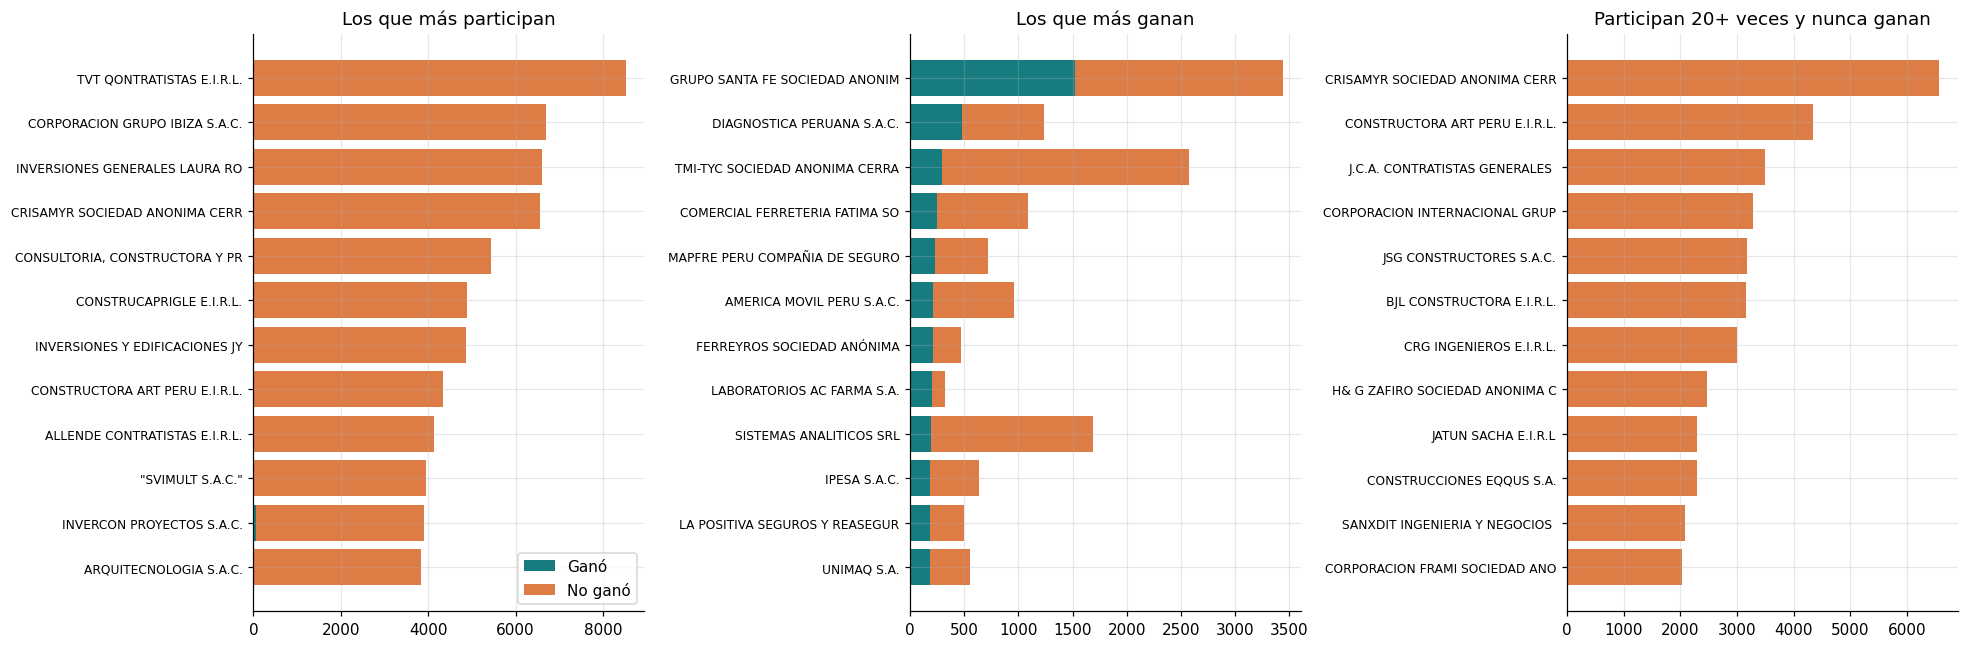

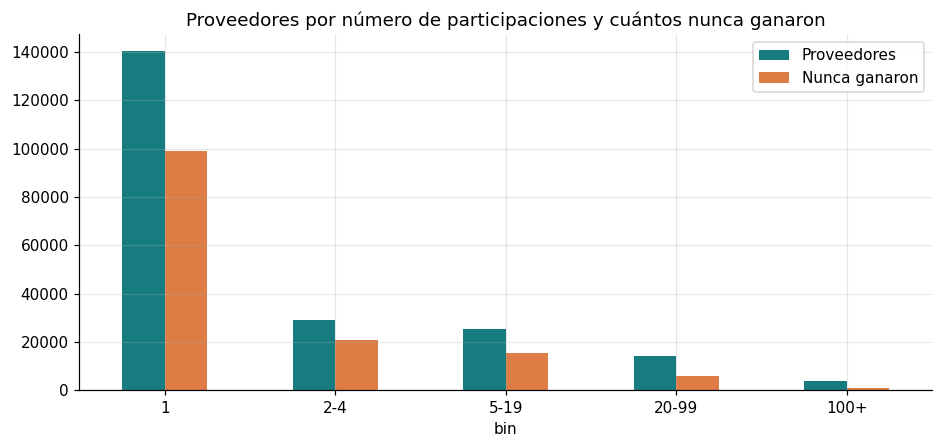

212 652 proveedores participan; 66.7% nunca ganó; tasa de victoria global 7.0%
✔ Ningún proveedor gana más procesos de los que participa
✔ Los rankings con nombre no incluyen personas naturales
✔ Quienes "nunca ganan" tienen cero victorias y el mínimo de participaciones


In [5]:
ranks = csv('eda/participation_rankings.csv')
ps = doc('eda/participation_summary.json')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (key, title) in zip(axes, [('mas_participan', 'Los que más participan'), ('mas_ganan', 'Los que más ganan'),
                                   ('nunca_ganan', f"Participan {ps['never_won_min']}+ veces y nunca ganan")]):
    r = ranks[ranks.ranking == key].head(12).iloc[::-1]
    ax.barh(r.name.str[:30], r.wins, color=TEAL, label='Ganó')
    ax.barh(r.name.str[:30], r.participations - r.wins, left=r.wins, color=ORANGE, label='No ganó')
    ax.set_title(title); ax.tick_params(axis='y', labelsize=8)
axes[0].legend(); plt.tight_layout(); plt.show()

bins = csv('eda/participation_bins.csv')
ax = bins.plot.bar(x='bin', y=['providers', 'never_won'], color=[TEAL, ORANGE], rot=0)
ax.set_title('Proveedores por número de participaciones y cuántos nunca ganaron'); ax.legend(['Proveedores', 'Nunca ganaron'])
plt.show()
print(f"{ps['providers']:,} proveedores participan; {ps['never_won_share']:.1%} nunca ganó; "
      f"tasa de victoria global {ps['overall_win_rate']:.1%}".replace(',', ' '))
check('EDA', 'Ningún proveedor gana más procesos de los que participa', bool((ranks.wins <= ranks.participations).all()))
check('EDA', 'Los rankings con nombre no incluyen personas naturales', not (ranks.type == 'persona_natural').any())
check('EDA', 'Quienes "nunca ganan" tienen cero victorias y el mínimo de participaciones',
      bool(((ranks.ranking != 'nunca_ganan') | ((ranks.wins == 0) & (ranks.participations >= ps['never_won_min']))).all()))

## 3. Spark: RDD frente a DataFrame, particionamiento y Spark frente a pandas

**Qué se afirma.** El DataFrame es más rápido que el RDD (Catalyst, Tungsten, sin serialización a Python); filtrar por
la columna de partición lee menos carpetas; con este volumen pandas gana en una agregación simple.

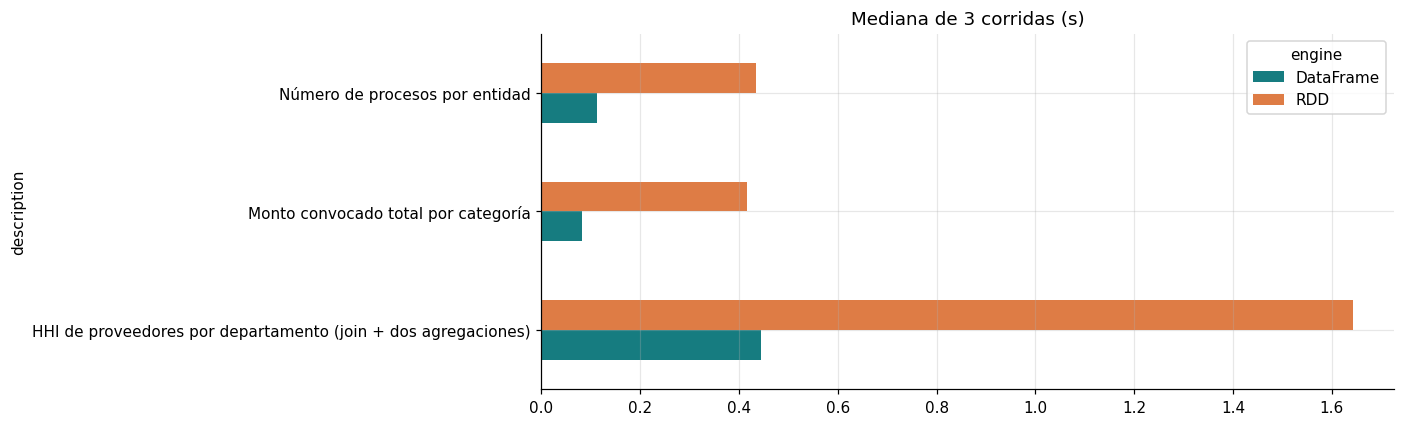

✔ El DataFrame es más rápido que el RDD en las tres operaciones — 3.7×, 5.1×, 3.9×
✔ RDD y DataFrame dan el mismo resultado
Filtro por año: 12 de 36 carpetas, 0.07 s frente a 0.09 s filtrando por fecha
✔ El partition pruning lee menos carpetas


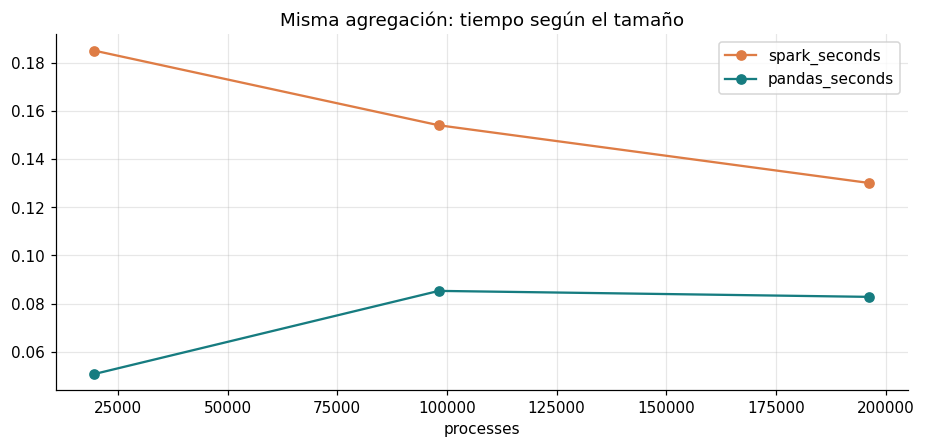

✔ Spark y pandas producen los mismos grupos


In [6]:
bench = csv('eda/rdd_dataframe_benchmark.csv')
pivot = bench.pivot(index='description', columns='engine', values='median_seconds')
pivot.plot.barh(color=[TEAL, ORANGE]); plt.title('Mediana de 3 corridas (s)'); plt.show()
check('Spark', 'El DataFrame es más rápido que el RDD en las tres operaciones', bool((pivot.DataFrame < pivot.RDD).all()),
      ', '.join(f'{v:.1f}×' for v in pivot.RDD / pivot.DataFrame))
check('Spark', 'RDD y DataFrame dan el mismo resultado', bool(bench.equivalent.all()))

part = doc('eda/partitioning_experiment.json')
pr = part['pruning']
print(f"Filtro por año: {pr['folders_read_with_pruning']} de {pr['folders_total']} carpetas, "
      f"{pr['partition_column']['seconds']:.2f} s frente a {pr['other_column']['seconds']:.2f} s filtrando por fecha")
check('Spark', 'El partition pruning lee menos carpetas', pr['folders_read_with_pruning'] < pr['folders_total'])

svp = csv('eda/spark_vs_pandas.csv')
ax = svp.plot(x='processes', y=['spark_seconds', 'pandas_seconds'], marker='o', color=[ORANGE, TEAL])
ax.set_title('Misma agregación: tiempo según el tamaño'); plt.show()
check('Spark', 'Spark y pandas producen los mismos grupos', bool((svp.groups_spark == svp.groups_pandas).all()))

## 4. Q1 · Concentración y decisión de no muestrear

**Qué se afirma.** Las municipalidades tienen el HHI mediano más alto. Ningún diseño de muestra conserva la respuesta:
muestrear procesos infla el HHI; muestrear entidades completas no lo sesga, pero solo encuentra una fracción de las
entidades concentradas.

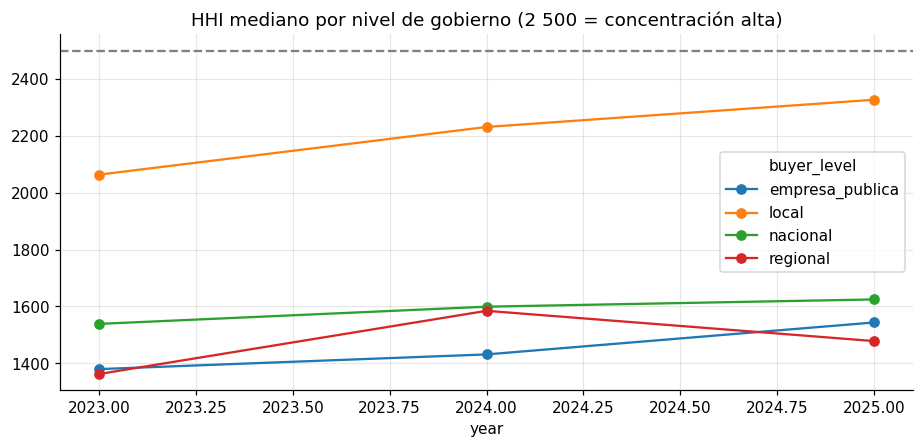

✔ Todos los HHI están entre 0 y 10 000
✔ Las municipalidades tienen el HHI mediano más alto — 2327


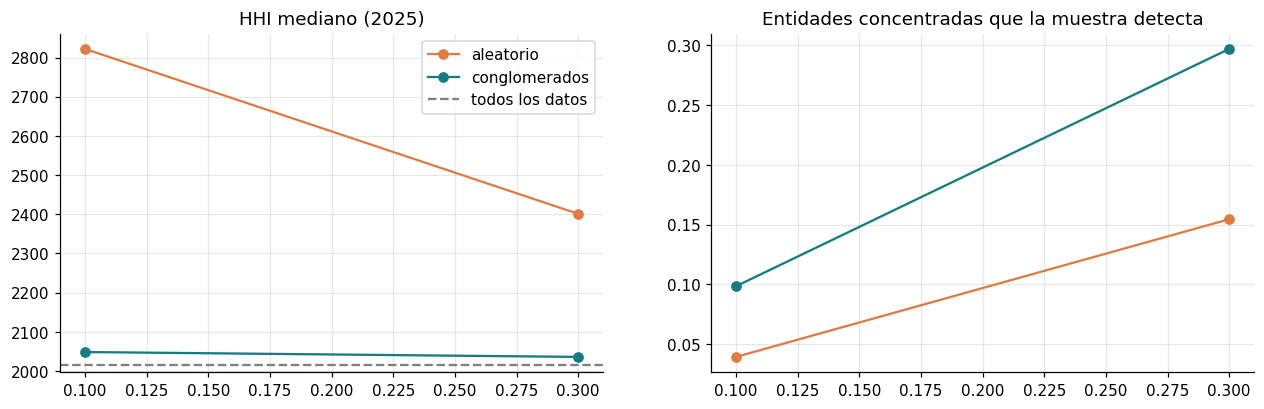

✔ Muestrear procesos al 10 % infla el HHI mediano — 2016 → 2822
✔ Muestrear entidades no sesga el HHI pero detecta solo ~10 % de las concentradas — HHI 2049, detecta 10%


In [7]:
hhi = csv('eda/buyer_hhi_summary.csv')
hhi = hhi[hhi.buyer_level.isin(['local', 'regional', 'nacional', 'empresa_publica'])]
hhi.pivot(index='year', columns='buyer_level', values='median_hhi').plot(marker='o')
plt.axhline(2500, ls='--', c='grey'); plt.title('HHI mediano por nivel de gobierno (2 500 = concentración alta)'); plt.show()
check('Q1', 'Todos los HHI están entre 0 y 10 000', validation['hhi_in_range'])
last = hhi[hhi.year == hhi.year.max()].set_index('buyer_level').median_hhi
check('Q1', 'Las municipalidades tienen el HHI mediano más alto', last.idxmax() == 'local', f"{last.max():.0f}")

effect = csv('eda/sampling_effect.csv')
y = effect.year.max()
e = effect[effect.year == y]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for design, color in [('aleatorio', ORANGE), ('conglomerados', TEAL)]:
    g = e[e.design == design].sort_values('fraction')
    axes[0].plot(g.fraction, g.median_hhi, marker='o', color=color, label=design)
    axes[1].plot(g.fraction, g.high_recall, marker='o', color=color, label=design)
full = e[e.design == 'todos'].iloc[0]
axes[0].axhline(full.median_hhi, ls='--', c='grey', label='todos los datos'); axes[0].set_title(f'HHI mediano ({y})')
axes[1].set_title('Entidades concentradas que la muestra detecta'); axes[0].legend(); plt.show()
rnd = e[(e.design == 'aleatorio') & (e.fraction == 0.1)].iloc[0]
clu = e[(e.design == 'conglomerados') & (e.fraction == 0.1)].iloc[0]
check('Q1', 'Muestrear procesos al 10 % infla el HHI mediano', rnd.median_hhi > full.median_hhi * 1.2,
      f'{full.median_hhi:.0f} → {rnd.median_hhi:.0f}')
check('Q1', 'Muestrear entidades no sesga el HHI pero detecta solo ~10 % de las concentradas',
      abs(clu.median_hhi / full.median_hhi - 1) < 0.15 and clu.high_recall < 0.2,
      f'HHI {clu.median_hhi:.0f}, detecta {clu.high_recall:.0%}')

## 5. Parte II · Jaccard, MinHash y LSH

**Qué se afirma.** El error de MinHash sigue la teoría √(J(1−J)/k); la curva S observada de LSH coincide con
1 − (1 − sʳ)ᵇ; LSH compara una fracción ínfima de los pares sobre todo el corpus.

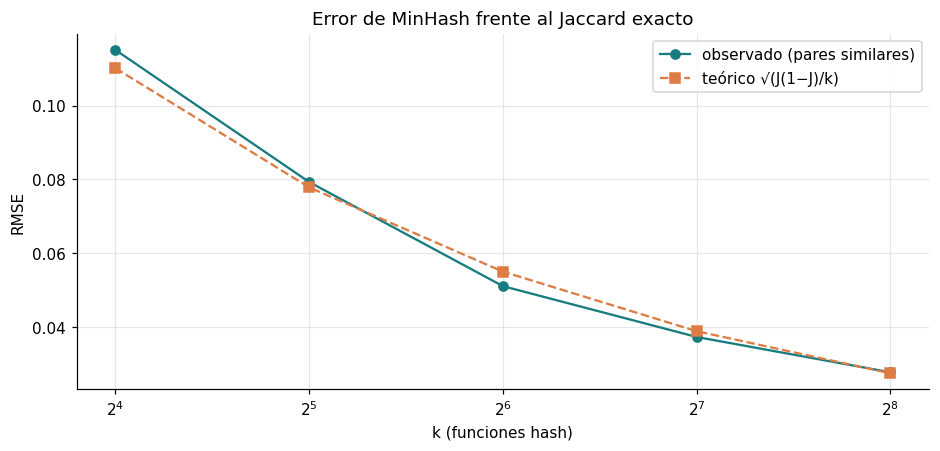

✔ El RMSE de MinHash está a menos de 15 % del teórico para todo k — 1.04, 1.02, 0.93, 0.96, 1.01


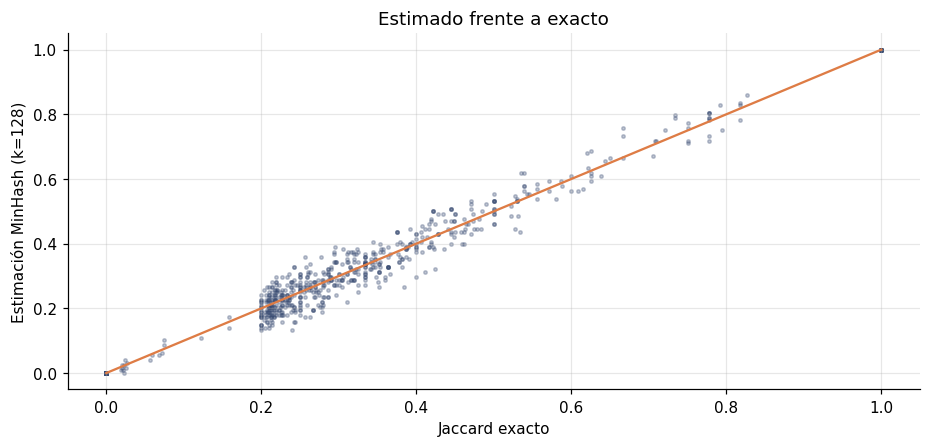

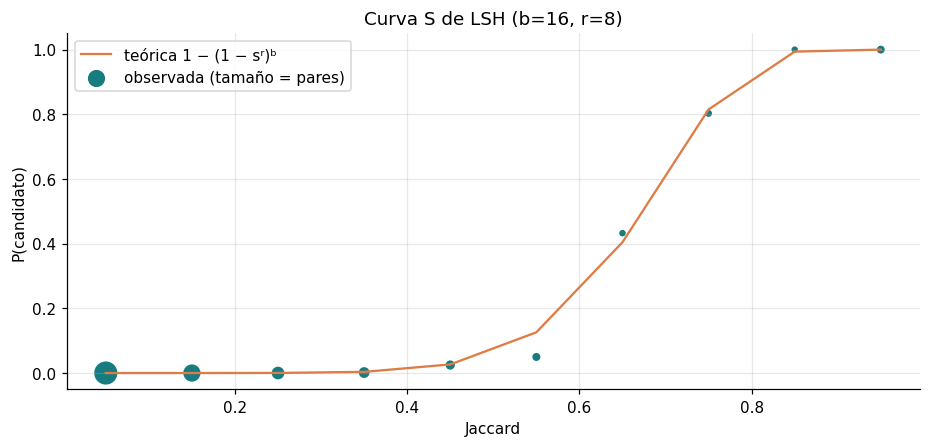

✔ La curva S observada sigue a la teórica (error medio < 0,1) — error medio 0.013
Corpus: 19 262 232 226 pares posibles → 198 160 candidatos → 130 168 con Jaccard ≥ 0.7
✔ LSH compara menos de 0,01 % de los pares posibles


In [8]:
err = csv('similarity/minhash_error.csv')
plt.plot(err.hashes, err.rmse_similar, 'o-', color=TEAL, label='observado (pares similares)')
plt.plot(err.hashes, err.rmse_theoretical_similar, 's--', color=ORANGE, label='teórico √(J(1−J)/k)')
plt.xscale('log', base=2); plt.xlabel('k (funciones hash)'); plt.ylabel('RMSE'); plt.legend()
plt.title('Error de MinHash frente al Jaccard exacto'); plt.show()
ratio = (err.rmse_similar / err.rmse_theoretical_similar)
check('Parte II', 'El RMSE de MinHash está a menos de 15 % del teórico para todo k', bool((abs(ratio - 1) < 0.15).all()),
      ', '.join(f'{v:.2f}' for v in ratio))

sc = csv('similarity/minhash_scatter.csv')
s128 = sc[sc.hashes == 128]
plt.scatter(s128.exact, s128.estimate, s=5, alpha=0.3, color=NAVY); plt.plot([0, 1], [0, 1], c=ORANGE)
plt.xlabel('Jaccard exacto'); plt.ylabel('Estimación MinHash (k=128)'); plt.title('Estimado frente a exacto'); plt.show()

curve = csv('similarity/s_curve_observed.csv')
c = curve[(curve.hashes == 128) & (curve.bands == 16) & (curve.rows == 8)]
plt.plot(c.similarity, c.theoretical, '-', color=ORANGE, label='teórica 1 − (1 − sʳ)ᵇ')
plt.scatter(c.similarity, c.observed, s=np.clip(np.sqrt(c.pairs), 10, 200), color=TEAL, label='observada (tamaño = pares)')
plt.xlabel('Jaccard'); plt.ylabel('P(candidato)'); plt.title('Curva S de LSH (b=16, r=8)'); plt.legend(); plt.show()
dense = c[c.pairs >= 50]
mae = (dense.observed - dense.theoretical).abs().mean()
check('Parte II', 'La curva S observada sigue a la teórica (error medio < 0,1)', mae < 0.1, f'error medio {mae:.3f}')

corpus = doc('similarity/methodology.json')['full_corpus']
print(f"Corpus: {corpus['possible_pairs']:,} pares posibles → {corpus['candidate_pairs']:,} candidatos → "
      f"{corpus['similar_pairs']:,} con Jaccard ≥ {corpus['threshold']}".replace(',', ' '))
check('Parte II', 'LSH compara menos de 0,01 % de los pares posibles',
      corpus['candidate_pairs'] / corpus['possible_pairs'] < 1e-4)

### 5.1 Etiquetas de LSH: grupos de requerimientos casi idénticos

**Qué se afirma.** Los pares verificados se unen en grupos (componentes conexas) y cada grupo recibe como etiqueta las
palabras que mejor lo distinguen del corpus (TF-IDF del grupo).

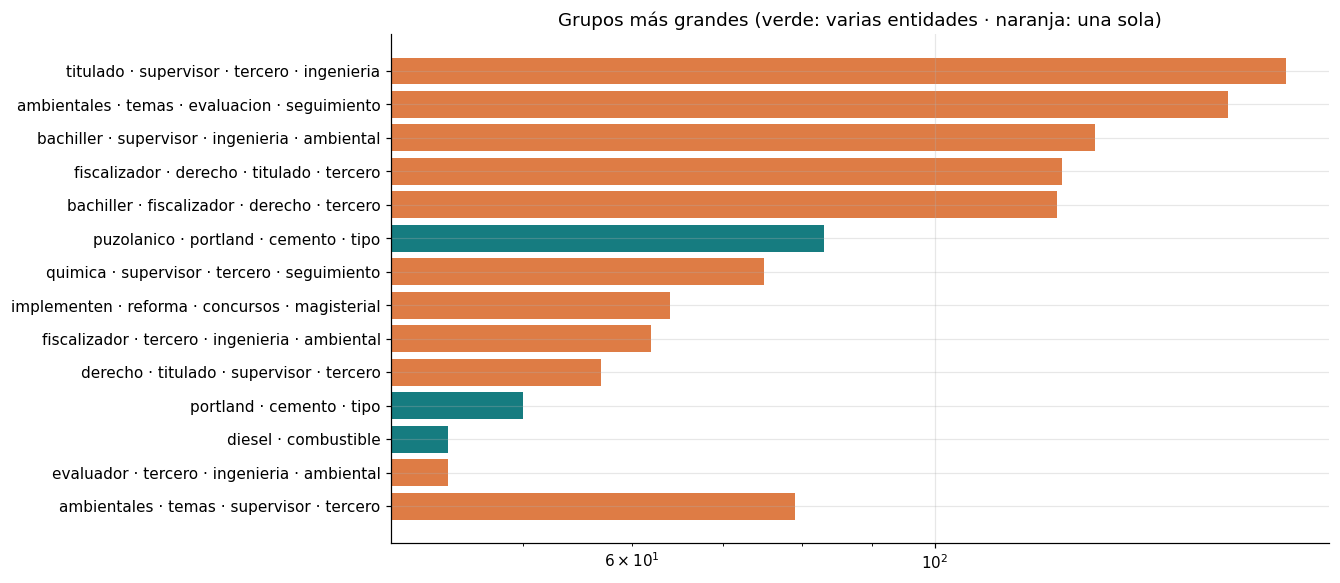

,group,label,processes,buyers,top_buyer,category,mean_jaccard
0,1,titulado · supervisor · tercero · ingenieria,181,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,0.988147
1,2,ambientales · temas · evaluacion · seguimiento,164,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,1.000000
2,3,bachiller · supervisor · ingenieria · ambiental,131,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,0.961750
3,4,fiscalizador · derecho · titulado · tercero,124,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,1.000000
4,5,bachiller · fiscalizador · derecho · tercero,123,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,1.000000
5,6,puzolanico · portland · cemento · tipo,83,43,GOBIERNO REGIONAL DE CUSCO SEDE CENTRAL,goods,0.802582
6,7,ambientales · temas · supervisor · tercero,79,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,0.952918
7,8,quimica · supervisor · tercero · seguimiento,75,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,0.878445
8,9,implementen · reforma · concursos · magisterial,64,1,PROGRAMA EDUCACION BASICA PARA TODOS UE 026,services,0.769204
9,10,fiscalizador · tercero · ingenieria · ambiental,62,1,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,services,0.894171


✔ Todos los grupos tienen al menos 3 procesos
✔ Las aristas de los grupos superan el umbral de casi idéntico


In [9]:
groups = csv('similarity/lsh_groups.csv')
gs = doc('similarity/lsh_groups_summary.json')
top = groups.head(15).iloc[::-1]
colors = [TEAL if b > 1 else ORANGE for b in top.buyers]
plt.figure(figsize=(11, 6)); plt.barh(top.label.fillna('—'), top.processes, color=colors)
plt.title('Grupos más grandes (verde: varias entidades · naranja: una sola)'); plt.xscale('log'); plt.show()
display(groups[['group', 'label', 'processes', 'buyers', 'top_buyer', 'category', 'mean_jaccard']].head(15))
check('Parte II', 'Todos los grupos tienen al menos 3 procesos', bool((groups.processes >= gs['min_group']).all()))
check('Parte II', 'Las aristas de los grupos superan el umbral de casi idéntico',
      bool((groups.mean_jaccard.dropna() >= corpus['threshold'] - 1e-9).all()))

## 6. Parte III · Búsqueda aproximada de vecinos (HNSW e IVF)

**Qué se afirma.** HNSW e IVF recuperan más del 95 % de los vecinos exactos y responden mucho más rápido; la ventaja
crece con el tamaño del corpus porque la búsqueda exacta es lineal en N.

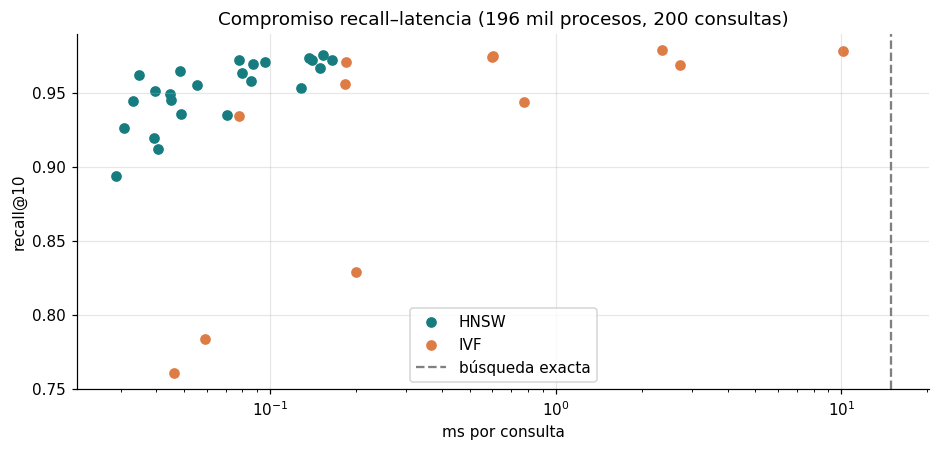

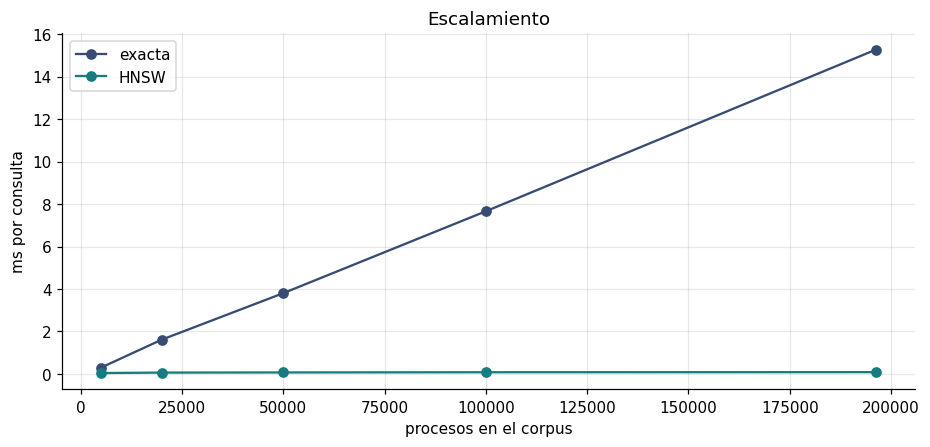

✔ Alguna configuración HNSW logra recall@10 ≥ 95 % — M16_efC128_efS16: 96.2%, 429× más rápida
✔ La búsqueda exacta crece con el corpus
✔ IVF con nprobe = nlist recupera casi todo (≥ 97 %)


In [10]:
hnsw, ivf = csv('ann/hnsw_grid.csv'), csv('ann/ivf_grid.csv')
plt.scatter(hnsw.mean_ms, hnsw.recall_at_10, color=TEAL, label='HNSW')
plt.scatter(ivf.mean_ms, ivf.recall_at_10, color=ORANGE, label='IVF')
plt.axvline(hnsw.exact_mean_ms.iloc[0], ls='--', c='grey', label='búsqueda exacta')
plt.xscale('log'); plt.xlabel('ms por consulta'); plt.ylabel('recall@10'); plt.legend()
plt.title('Compromiso recall–latencia (196 mil procesos, 200 consultas)'); plt.show()

scaling = csv('ann/scaling.csv')
plt.plot(scaling.corpus_size, scaling.exact_mean_ms, 'o-', color=NAVY, label='exacta')
plt.plot(scaling.corpus_size, scaling.hnsw_mean_ms, 'o-', color=TEAL, label='HNSW')
plt.xlabel('procesos en el corpus'); plt.ylabel('ms por consulta'); plt.legend(); plt.title('Escalamiento'); plt.show()
best = doc('ann/methodology.json')['best_hnsw']
check('Parte III', 'Alguna configuración HNSW logra recall@10 ≥ 95 %', bool((hnsw.recall_at_10 >= 0.95).any()),
      f"{best['config']}: {best['recall_at_10']:.1%}, {best['speedup']:.0f}× más rápida")
check('Parte III', 'La búsqueda exacta crece con el corpus', validation['exact_search_grows_with_corpus'])
check('Parte III', 'IVF con nprobe = nlist recupera casi todo (≥ 97 %)',
      bool((ivf[ivf.nprobe == ivf.nlist].recall_at_10 >= 0.97).all()) if (ivf.nprobe == ivf.nlist).any() else True)

## 7. Parte IV · Flujos: Bloom, Count-Min, DGIM y la simulación con Structured Streaming

**Qué se afirma.** Con la misma ocupación del filtro, el FPR del Bloom coincide con (1 − e^(−kn/m))^k y nunca hay falsos
negativos; Count-Min nunca subestima y cumple su cota ε·N; DGIM no supera el 50 % de error. La simulación con Spark
Structured Streaming procesa todo el flujo, una semana por micro-lote.

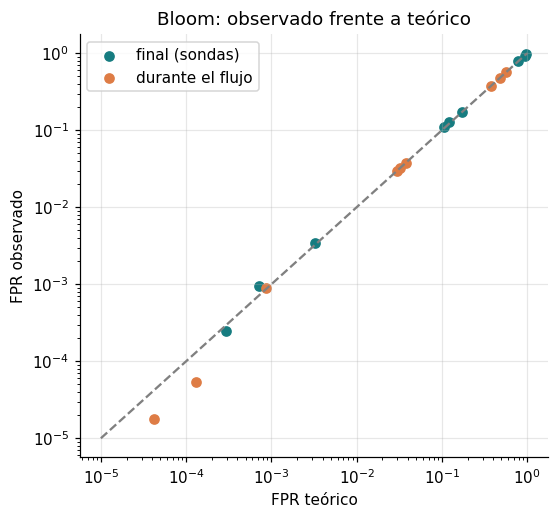

✔ Bloom sin falsos negativos
✔ FPR del Bloom a menos de 2 pp de la teoría con la misma ocupación


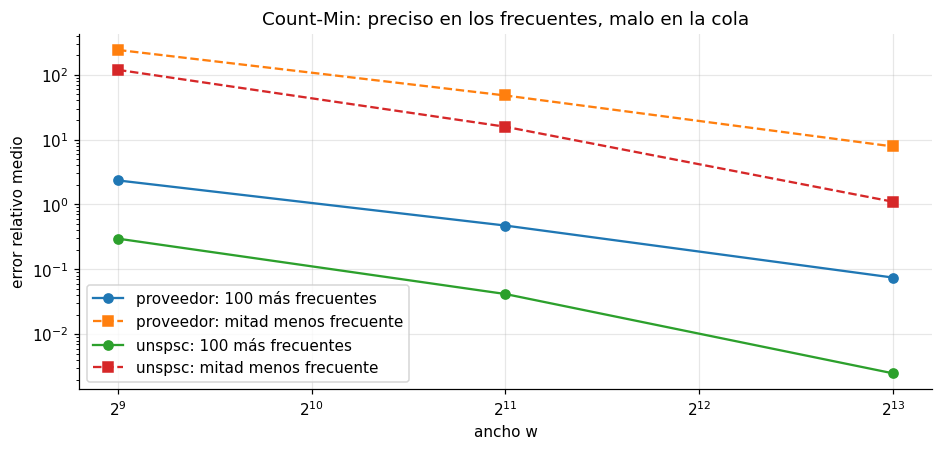

✔ Count-Min nunca subestima
✔ Count-Min cumple la cota ε·N con la probabilidad prometida


,signal,unit,window,exact,estimate,relative_error,buckets,bytes,exact_bytes
0,postor_unico,eventos,1000,301,315.0,0.046512,13,208,16000
1,postor_unico,eventos,10000,1409,1611.0,0.143364,15,240,160000
2,postor_unico,días,7,58,51.0,0.120690,8,128,1056
3,postor_unico,días,30,396,459.0,0.159091,12,192,27520
4,alto_monto,eventos,1000,99,103.0,0.040404,9,144,16000
5,alto_monto,eventos,10000,1184,1399.0,0.181588,15,240,160000
6,alto_monto,días,7,9,10.0,0.111111,5,80,1056
7,alto_monto,días,30,190,247.0,0.300000,11,176,27520


✔ DGIM con error relativo ≤ 50 % en todas las ventanas — máximo 30.0%


In [11]:
bloom = csv('streaming/bloom_grid.csv')
plt.figure(figsize=(5.5, 5)); plt.plot([1e-5, 1], [1e-5, 1], c='grey', ls='--')
plt.scatter(bloom.theoretical_fpr, bloom.final_fpr, color=TEAL, label='final (sondas)')
plt.scatter(bloom.expected_stream_fpr, bloom.observed_fpr, color=ORANGE, label='durante el flujo')
plt.xscale('log'); plt.yscale('log'); plt.xlabel('FPR teórico'); plt.ylabel('FPR observado'); plt.legend()
plt.title('Bloom: observado frente a teórico'); plt.show()
check('Parte IV', 'Bloom sin falsos negativos', bool((bloom.fn == 0).all()))
check('Parte IV', 'FPR del Bloom a menos de 2 pp de la teoría con la misma ocupación', validation['bloom_matches_theory'])

cms = csv('streaming/cms_grid.csv')
for domain, g in cms.groupby('domain'):
    g = g[g.depth == 5]
    plt.plot(g.width, g.heavy_mean_relative_error, 'o-', label=f'{domain}: 100 más frecuentes')
    plt.plot(g.width, g.tail_mean_relative_error, 's--', label=f'{domain}: mitad menos frecuente')
plt.xscale('log', base=2); plt.yscale('log'); plt.xlabel('ancho w'); plt.ylabel('error relativo medio'); plt.legend()
plt.title('Count-Min: preciso en los frecuentes, malo en la cola'); plt.show()
check('Parte IV', 'Count-Min nunca subestima', bool((cms.underestimates == 0).all()))
check('Parte IV', 'Count-Min cumple la cota ε·N con la probabilidad prometida', bool((cms.within_bound >= cms.guaranteed).all()))

dgim = csv('streaming/dgim_grid.csv')
display(dgim[['signal', 'unit', 'window', 'exact', 'estimate', 'relative_error', 'buckets', 'bytes', 'exact_bytes']])
check('Parte IV', 'DGIM con error relativo ≤ 50 % en todas las ventanas', bool((dgim.relative_error.dropna() <= 0.5).all()),
      f'máximo {dgim.relative_error.max():.1%}')

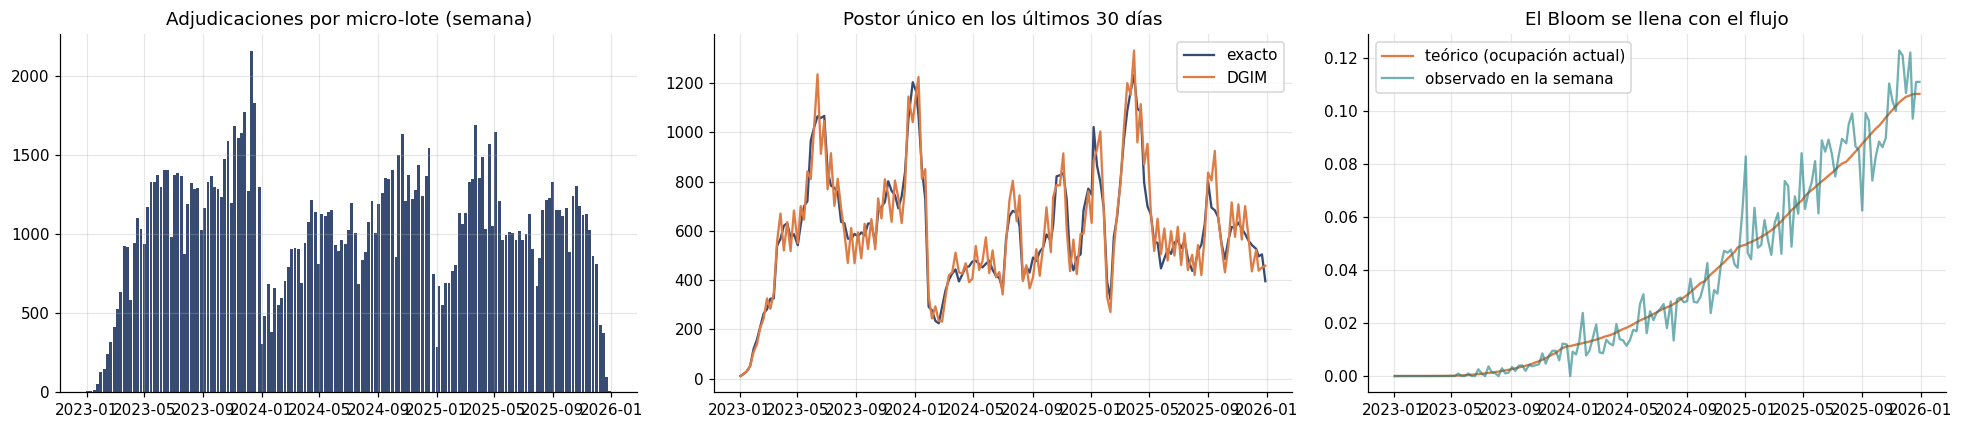

Spark Structured Streaming (fuente de archivos Parquet  maxFilesPerTrigger=1  Trigger.AvailableNow  foreachBatch): 157 micro-lotes  161 255 eventos en 28 s (5 710 eventos/s)
✔ La simulación con Structured Streaming procesa todos los eventos del flujo — 161255 = 161255
✔ Los micro-lotes llegan en orden cronológico
✔ DGIM ≤ 50 % de error en cada micro-lote (con al menos 10 en la ventana)


In [12]:
replay = csv('streaming/replay_batches.csv')
rs = doc('streaming/replay_summary.json')
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
weeks = pd.to_datetime(replay.week_start)
axes[0].bar(weeks, replay.events, width=6, color=NAVY); axes[0].set_title('Adjudicaciones por micro-lote (semana)')
axes[1].plot(weeks, replay.dgim_exact, color=NAVY, label='exacto'); axes[1].plot(weeks, replay.dgim_estimate, color=ORANGE, label='DGIM')
axes[1].set_title('Postor único en los últimos 30 días'); axes[1].legend()
axes[2].plot(weeks, replay.bloom_fpr_theoretical, color=ORANGE, label='teórico (ocupación actual)')
axes[2].plot(weeks, replay.bloom_fpr_batch, color=TEAL, alpha=0.6, label='observado en la semana')
axes[2].set_title('El Bloom se llena con el flujo'); axes[2].legend(); plt.tight_layout(); plt.show()
print(f"{rs['engine']}: {rs['batches']} micro-lotes, {rs['events']:,} eventos en {rs['wall_seconds']:.0f} s "
      f"({rs['events_per_second']:,.0f} eventos/s)".replace(',', ' '))
stream_events = doc('streaming/methodology.json')['events']
check('Parte IV', 'La simulación con Structured Streaming procesa todos los eventos del flujo', rs['events'] == stream_events,
      f"{rs['events']} = {stream_events}")
check('Parte IV', 'Los micro-lotes llegan en orden cronológico', bool(weeks.is_monotonic_increasing))
check('Parte IV', 'DGIM ≤ 50 % de error en cada micro-lote (con al menos 10 en la ventana)',
      bool((replay[replay.dgim_exact >= 10].dgim_relative_error <= 0.5).all()))

## 8. Parte V · Conjuntos frecuentes y reglas de asociación

**Qué se afirma.** Apriori y FP-Growth encuentran exactamente los mismos conjuntos; las reglas seleccionadas son
informativas (no repiten la ley) y superan a sus versiones más simples (improvement).

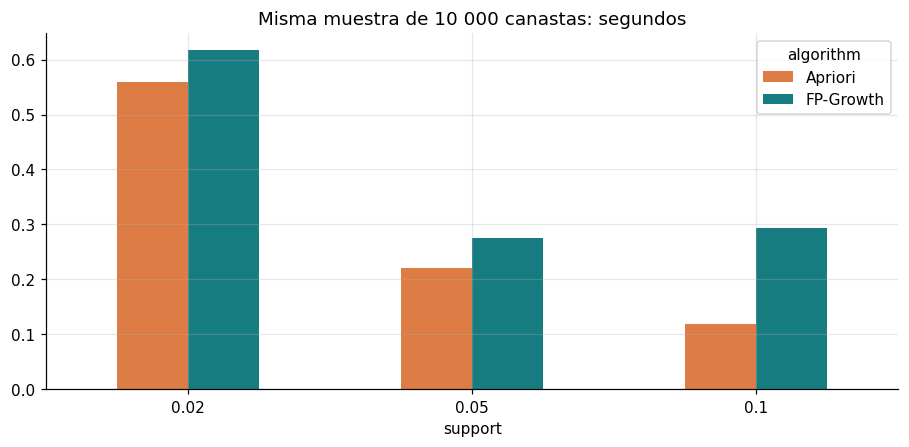

✔ Apriori y FP-Growth encuentran los mismos conjuntos en los tres soportes


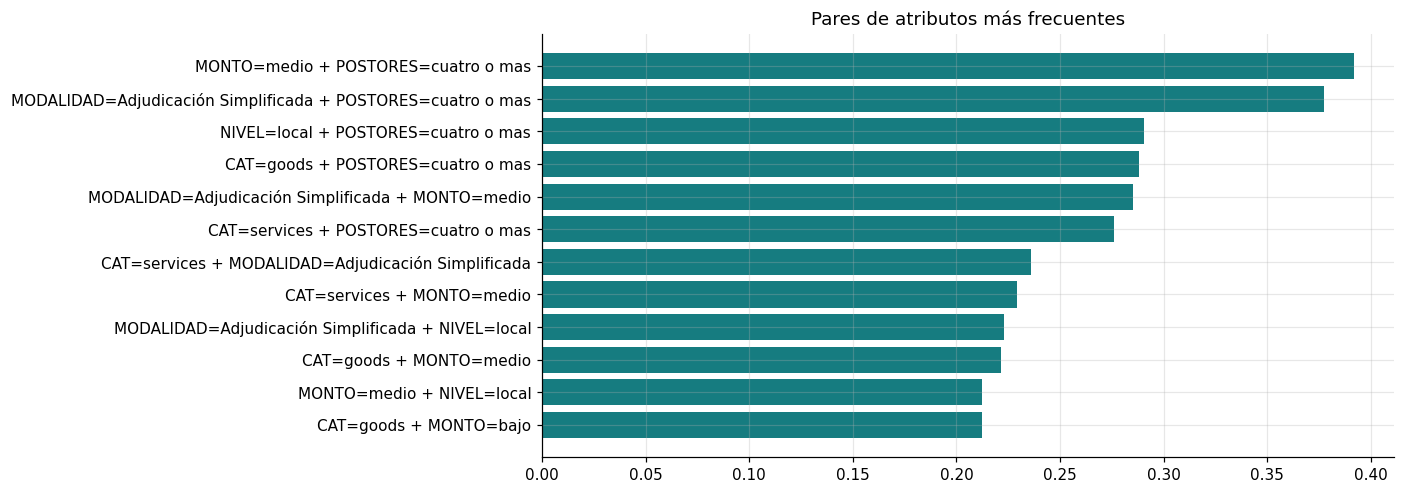

,conjuntos frecuentes (soporte ≥ 2 %)
size,
1,40
2,153
3,177
4,97
5,20
6,1


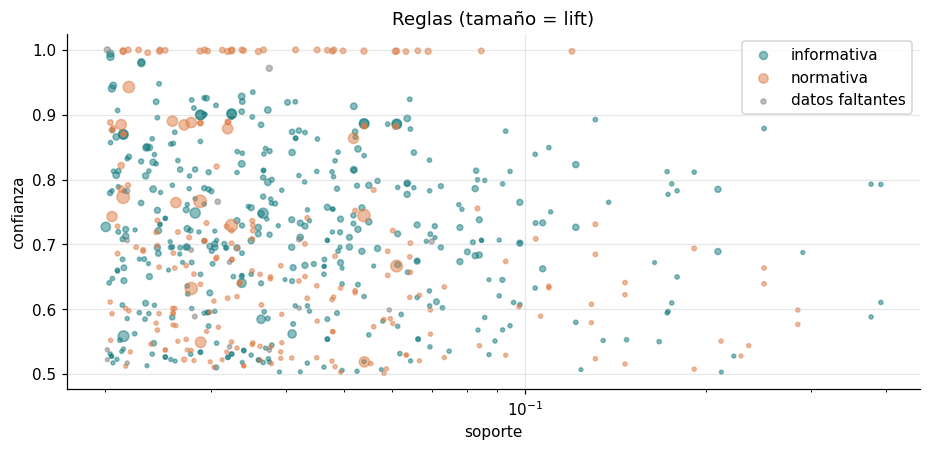

,source,rule_id,support,confidence,lift,improvement
0,general,NIVEL=regional ∧ POSTORES=dos a tres → MODALIDAD=Comparación de Precios,0.021,0.558,8.070,0.128
1,general,MONTO=alto ∧ NIVEL=local → CAT=works,0.037,0.748,7.334,0.310
2,general,MODALIDAD=Régimen o procedimiento especial → POSTORES=uno,0.020,0.727,6.238,0.610
3,general,MODALIDAD=Comparación de Precios → POSTORES=dos a tres,0.061,0.885,6.225,0.743
4,general,DEP=LIMA ∧ MODALIDAD=Régimen o procedimiento especial → NIVEL=nacional,0.023,0.980,3.665,0.131
5,postor único (Q2),CAT=goods ∧ MODALIDAD=Adjudicación Simplificada ∧ NIVEL=local → POSTORES=uno,0.004,0.050,3.015,0.020
6,postor único (Q2),DEP=LIMA ∧ NIVEL=nacional → POSTORES=uno,0.004,0.024,1.460,0.003
7,postor único (Q2),MODALIDAD=Subasta Inversa Electrónica → POSTORES=uno,0.003,0.024,1.440,0.007
8,postor único (Q2),MONTO=bajo → POSTORES=uno,0.007,0.023,1.419,0.007


✔ Hay al menos 8 reglas seleccionadas — 9
✔ Todas las reglas seleccionadas son informativas y tienen lift > 1
✔ Las reglas generales superan en ≥ 5 puntos a sus sub-reglas


In [13]:
algos = csv('association/algorithm_benchmark.csv')
same = algos[algos.scope == 'same_sample'].pivot(index='support', columns='algorithm', values='seconds')
same.plot.bar(rot=0, color=[ORANGE, TEAL]); plt.title('Misma muestra de 10 000 canastas: segundos'); plt.show()
check('Parte V', 'Apriori y FP-Growth encuentran los mismos conjuntos en los tres soportes',
      bool(algos[algos.scope == 'same_sample'].equivalent.all()))

itemsets = csv('association/frequent_itemsets_fpgrowth.csv')
it = itemsets[(itemsets.min_support == 0.02)].copy()
it['size'] = it['items'].map(lambda s: len(json.loads(s)))
pairs_ = it[it['size'] == 2].sort_values('support', ascending=False).head(12).iloc[::-1]
plt.figure(figsize=(10, 5)); plt.barh(pairs_['items'].map(lambda s: ' + '.join(json.loads(s))), pairs_.support, color=TEAL)
plt.title('Pares de atributos más frecuentes'); plt.show()
display(it.groupby('size').size().rename('conjuntos frecuentes (soporte ≥ 2 %)').to_frame())

rules = csv('association/rules.csv')
r = rules[rules.year == 'Todos']
for kind, color in [('informativa', TEAL), ('normativa', ORANGE), ('datos faltantes', 'grey')]:
    g = r[r.kind == kind]; plt.scatter(g.support, g.confidence, s=g.lift * 6, alpha=0.5, color=color, label=kind)
plt.xscale('log'); plt.xlabel('soporte'); plt.ylabel('confianza'); plt.legend(); plt.title('Reglas (tamaño = lift)'); plt.show()

selected = pd.DataFrame(doc('association/selected_rules.json')['rules'])
display(selected[['source', 'rule_id', 'support', 'confidence', 'lift', 'improvement']].round(3))
check('Parte V', 'Hay al menos 8 reglas seleccionadas', len(selected) >= 8, str(len(selected)))
check('Parte V', 'Todas las reglas seleccionadas son informativas y tienen lift > 1',
      bool((selected.kind == 'informativa').all() and (selected.lift > 1).all()))
general = selected[selected.source == 'general']
check('Parte V', 'Las reglas generales superan en ≥ 5 puntos a sus sub-reglas', bool((general.improvement >= 0.05).all()))

1 309 procesos (0.8%) piden ítems de más de un segmento


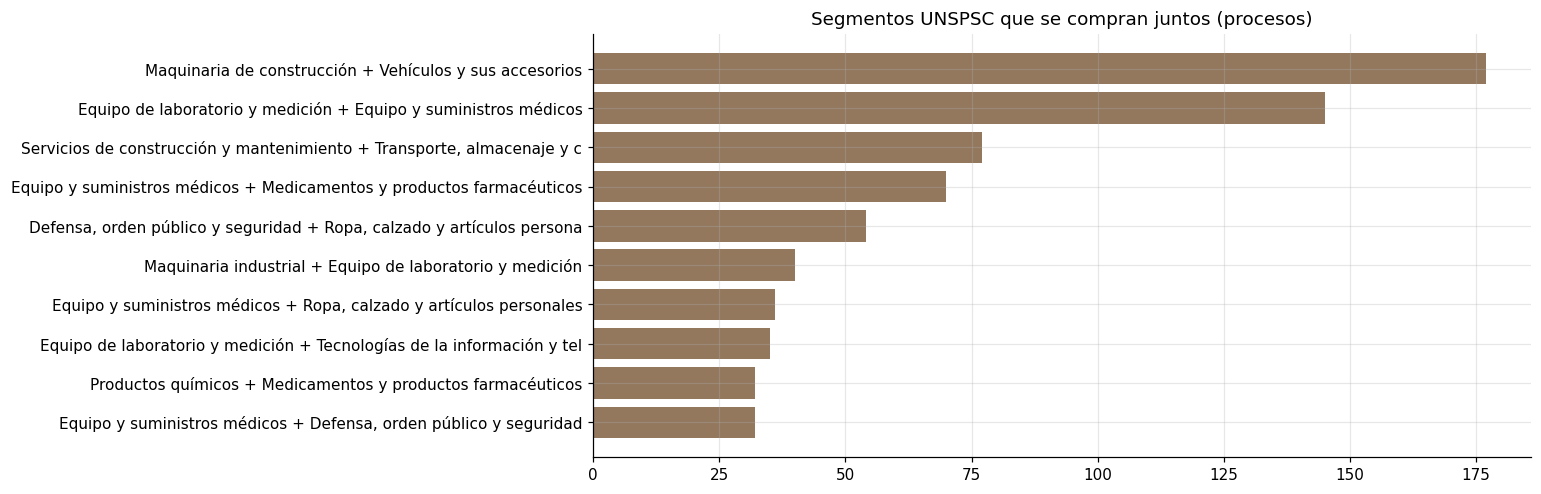

✔ Todo conjunto de compra conjunta frecuente tiene al menos el mínimo de procesos


In [14]:
co = csv('association/copurchase_itemsets.csv')
cs = doc('association/copurchase_summary.json')
print(f"{cs['multi_segment_baskets']:,} procesos ({cs['multi_segment_share']:.1%}) piden ítems de más de un segmento".replace(',', ' '))
pairs_co = co[co['size'] >= 2].head(10).iloc[::-1]
if len(pairs_co):
    plt.figure(figsize=(11, 5)); plt.barh(pairs_co.names.str[:70], pairs_co['count'], color=BROWN)
    plt.title('Segmentos UNSPSC que se compran juntos (procesos)'); plt.show()
check('Parte V', 'Todo conjunto de compra conjunta frecuente tiene al menos el mínimo de procesos',
      bool((co['count'] >= cs['min_count']).all()))

## 9. Q2 · ¿La modalidad explica el postor único entre compras parecidas?

**Qué se afirma.** La contratación directa mantiene una tasa mucho mayor de un solo participante cuando se compara con
las modalidades competitivas dentro de la misma categoría, departamento, año y banda de monto. La rejilla LSH, además,
se repite con otras muestras por bloques para ver cuánto depende de las entidades elegidas: depende bastante, y la
muestra principal resulta ser el mejor caso.

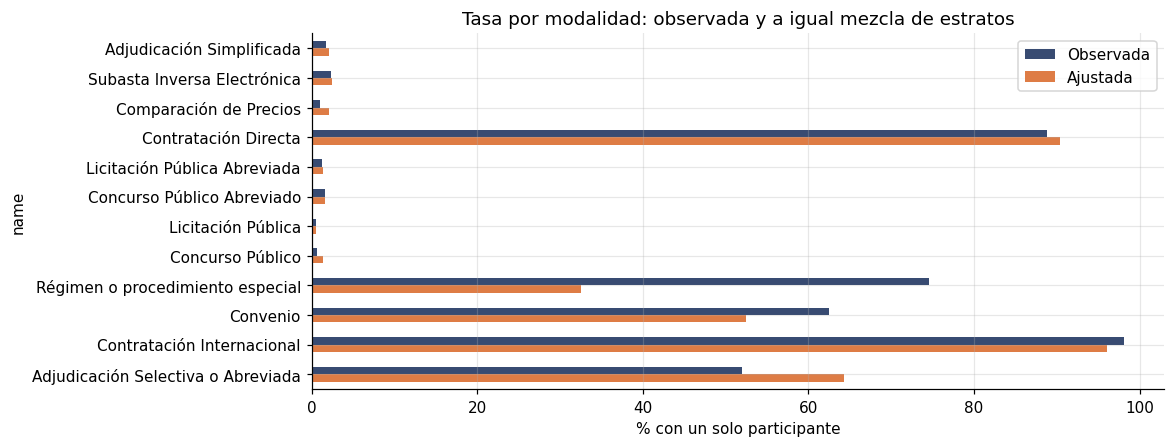

✔ La tasa observada por modalidad coincide con la de la tabla de postores
✔ Contratación directa supera a las competitivas en todos los estratos comparables — 108 de 108 estratos


,config,samples,f1_mean,f1_min,f1_max,f1_std,recall_min,recall_max,truth_pairs_min,truth_pairs_max
11,h32_b4_r8_t0.8,5,0.834,0.756,0.912,0.060,0.908,0.968,309,415
33,h128_b16_r8_t0.6,5,0.802,0.722,0.892,0.071,0.652,0.851,457,1374
22,h64_b8_r8_t0.7,5,0.797,0.707,0.885,0.073,0.723,0.933,358,755
10,h32_b4_r8_t0.7,5,0.786,0.694,0.882,0.071,0.599,0.869,358,755
34,h128_b16_r8_t0.7,5,0.773,0.674,0.902,0.092,0.832,0.963,358,755
23,h64_b8_r8_t0.8,5,0.765,0.642,0.884,0.087,0.945,0.997,309,415
21,h64_b8_r8_t0.6,5,0.751,0.633,0.866,0.100,0.486,0.801,457,1374
4,h32_b8_r4_t0.5,5,0.714,0.667,0.828,0.062,0.605,0.883,652,2556


h128_b16_r8_t0.7: F1 de 0.67 a 0.90 (media 0.77) y recall de 83% a 96% en 5 muestras. La muestra principal es el mejor caso.
✔ Cada configuración de la rejilla se evaluó en todas las muestras por bloques


In [15]:
adj = csv('eda/single_bidder_adjusted.csv'); per = doc('eda/single_bidder_persistence.json')
mod = adj[(adj.level == 'modalidad') & (adj.informed >= 1000)].set_index('name')
ax = (mod[['raw_rate', 'adjusted_rate']] * 100).rename(columns={'raw_rate': 'Observada', 'adjusted_rate': 'Ajustada'}).plot.barh(color=[NAVY, ORANGE])
ax.invert_yaxis(); ax.set_xlabel('% con un solo participante'); ax.set_title('Tasa por modalidad: observada y a igual mezcla de estratos'); plt.show()
bm = csv('eda/bidders_by_modality.csv').set_index('modality')
check('Q2', 'La tasa observada por modalidad coincide con la de la tabla de postores',
      bool(np.allclose(mod.raw_rate, bm.single_share.reindex(mod.index), atol=1e-9)))
check('Q2', 'Contratación directa supera a las competitivas en todos los estratos comparables',
      per['strata_where_direct_is_higher'] == per['comparable_strata'] > 0,
      f"{per['strata_where_direct_is_higher']} de {per['comparable_strata']} estratos")

stab = csv('similarity/lsh_stability.csv'); best = csv('similarity/lsh_parameter_grid.csv').sort_values(['f1', 'recall']).iloc[-1]
row = stab[stab.config == best.config].iloc[0]
display(stab.sort_values('f1_mean', ascending=False).head(8).round(3))
print(f'{best.config}: F1 de {row.f1_min:.2f} a {row.f1_max:.2f} (media {row.f1_mean:.2f}) y recall de '
      f'{row.recall_min:.0%} a {row.recall_max:.0%} en {int(row.samples)} muestras. La muestra principal es el mejor caso.')
check('Parte II', 'Cada configuración de la rejilla se evaluó en todas las muestras por bloques',
      bool((stab.samples == stab.samples.max()).all()) and stab.samples.max() >= 5)

## 10. Q4 · Señales de riesgo por proceso

**Qué se afirma.** Cuatro señales marcan procesos para revisar: un solo participante reportado en modalidades
competitivas, contratación directa, proveedor dominante y compra repetida detectada por LSH. Son poco frecuentes y
algunas coinciden más de lo esperable por azar. Ninguna prueba una irregularidad.

**Comprobación.** Las señales se vuelven a calcular aquí con pandas, a partir de las tablas Parquet y de los pares de la
Parte II, sin usar el código de Spark de `src/signals`. Si las tablas procesadas no están disponibles, se comprueba solo
la coherencia interna de los artefactos.

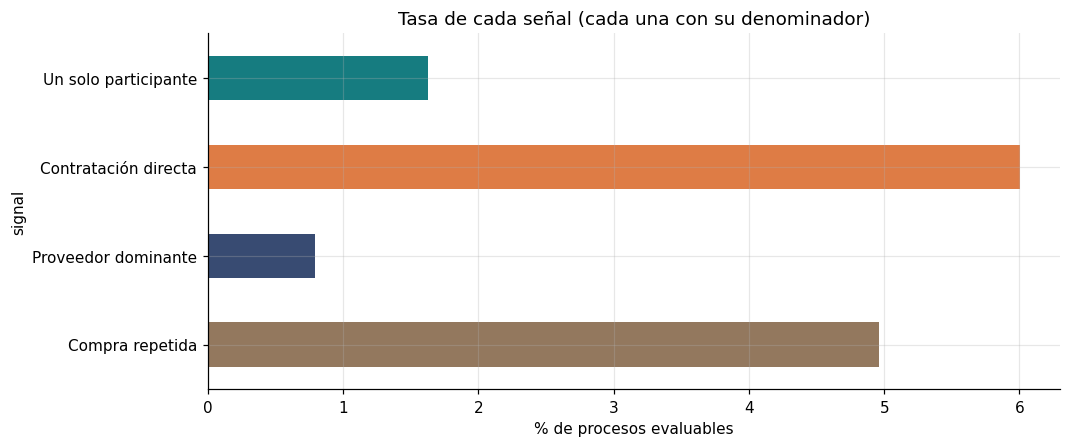

,label_a,label_b,evaluable_both,joint,expected_joint,lift
0,Un solo participante,Contratación directa,151182,NaN,NaN,NaN
1,Un solo participante,Proveedor dominante,89811,7.0,6.30,1.11
2,Un solo participante,Compra repetida,151182,188.0,83.35,2.26
3,Contratación directa,Proveedor dominante,110787,154.0,67.76,2.27
4,Contratación directa,Compra repetida,196277,924.0,584.43,1.58
5,Proveedor dominante,Compra repetida,110787,27.0,52.94,0.51


✔ Cada proceso se cuenta una sola vez en la distribución de señales
✔ Ninguna señal marca más procesos de los que puede evaluar


,evaluable,flagged,evaluable_spark,flagged_spark
single_bidder,151182,2461,151182,2461
direct,196277,11782,196277,11782
dominant_supplier,110787,874,110787,874
repeated_purchase,196277,9736,196277,9736


✔ El recálculo con pandas da los mismos evaluables y marcados que Spark
✔ Los lifts de coincidencia recalculados coinciden con los publicados — diferencia máxima 4.4e-16


In [16]:
S = csv('integrity/summary.csv'); S = S[S.year.astype(str) == 'Todos'].set_index('signal')
CO = csv('integrity/cooccurrence.csv'); M = doc('integrity/methodology.json')
ax = (S.rate * 100).rename(index=S.label).plot.barh(color=[TEAL, ORANGE, NAVY, BROWN]); ax.invert_yaxis()
ax.set_xlabel('% de procesos evaluables'); ax.set_title('Tasa de cada señal (cada una con su denominador)'); plt.show()
display(CO[['label_a', 'label_b', 'evaluable_both', 'joint', 'expected_joint', 'lift']].round(2))

counts = csv('integrity/count_distribution.csv')
check('Q4', 'Cada proceso se cuenta una sola vez en la distribución de señales', counts.processes.sum() == M['processes'])
check('Q4', 'Ninguna señal marca más procesos de los que puede evaluar', bool((S.flagged <= S.evaluable).all()))

DATA = next((p for p in [Path('../data/processed'), Path('data/processed'), Path('/data/processed')] if p.is_dir()), None)
if DATA is None:
    print('Tablas procesadas no disponibles: se omite el recálculo independiente')
else:
    P = pd.read_parquet(DATA / 'processes', columns=['ocid', 'modality', 'bidders', 'normalized_text'])
    A = pd.read_parquet(DATA / 'suppliers', columns=['ocid', 'year', 'buyer_id', 'supplier_id', 'allocated_amount_pen'])
    A = A.dropna(subset=['allocated_amount_pen', 'supplier_id', 'buyer_id'])
    A['year'] = A.year.astype(int)  # la partición llega como categoría y multiplicaría los grupos vacíos
    R = pd.read_parquet(ART / 'similarity/repeated_requirements.parquet',
                        columns=['left', 'right', 'kind', 'reconvocation', 'same_procedure'])
    competitive = P.modality.isin(M['competitive_modalities']) & P.bidders.notna()
    P['single_bidder'] = (P.bidders == 1).where(competitive).astype('float')
    P['direct'] = (P.modality == 'Contratación Directa').astype('float')
    # Proveedor dominante: parte del monto anual de la entidad, en entidades con suficientes adjudicaciones
    buyer = A.groupby(['year', 'buyer_id']).agg(total=('allocated_amount_pen', 'sum'), awards=('ocid', 'nunique'))
    pair = A.groupby(['year', 'buyer_id', 'supplier_id']).allocated_amount_pen.sum().rename('amount').reset_index()
    pair = pair.join(buyer[(buyer.awards >= M['min_buyer_awards']) & (buyer.total > 0)], on=['year', 'buyer_id'], how='inner')
    pair['share'] = pair.amount / pair.total
    top = A[['ocid', 'year', 'buyer_id', 'supplier_id']].drop_duplicates().merge(pair, on=['year', 'buyer_id', 'supplier_id'])
    P['dominant_supplier'] = P.ocid.map((top.groupby('ocid').share.max() >= M['dominant_share']).astype('float'))
    short = R[(R.kind == 'misma entidad, <= 30 días') & ~R.reconvocation & ~R.same_procedure]
    repeated = set(short.left) | set(short.right)
    P['repeated_purchase'] = P.ocid.isin(repeated).where(P.normalized_text.str.len() > 0).astype('float')
    again = pd.DataFrame({s: dict(evaluable=int(P[s].notna().sum()), flagged=int(P[s].sum())) for s in S.index}).T
    display(again.join(S[['evaluable', 'flagged']], rsuffix='_spark'))
    check('Q4', 'El recálculo con pandas da los mismos evaluables y marcados que Spark',
          bool((again.evaluable == S.evaluable).all() and (again.flagged == S.flagged).all()))
    lifts = []
    for r in CO.dropna(subset=['lift']).itertuples():
        both = P[P[r.signal_a].notna() & P[r.signal_b].notna()]
        expected = both[r.signal_a].sum() * both[r.signal_b].sum() / len(both)
        lifts.append(abs((both[r.signal_a] * both[r.signal_b]).sum() / expected - r.lift))
    check('Q4', 'Los lifts de coincidencia recalculados coinciden con los publicados', max(lifts) < 1e-9,
          f'diferencia máxima {max(lifts):.1e}')

## 11. Resumen de comprobaciones

In [17]:
summary = pd.DataFrame(CHECKS)
print(f"{(summary.resultado == '✔').sum()} de {len(summary)} comprobaciones se cumplen")
display(summary)

45 de 45 comprobaciones se cumplen


,parte,comprobación,resultado,detalle
0,Datos,Cada ocid aparece una sola vez,✔,
1,Datos,El monto repartido entre proveedores conserva el total adjudicado,✔,
2,Datos,Los totales del EDA coinciden con la tabla de procesos,✔,
3,Datos,Ningún monto negativo entra al análisis,✔,
4,EDA,En cada año y categoría la media supera a la mediana (cola larga a la derecha),✔,
5,EDA,Los ítems por segmento suman los ítems con código,✔,194 202 ítems
6,EDA,Ningún proveedor gana más procesos de los que participa,✔,
7,EDA,Los rankings con nombre no incluyen personas naturales,✔,
8,EDA,"Quienes ""nunca ganan"" tienen cero victorias y el mínimo de participaciones",✔,
9,Spark,El DataFrame es más rápido que el RDD en las tres operaciones,✔,"3.7×, 5.1×, 3.9×"


**Cómo leer este resumen.** Los controles verifican que cada técnica hace lo que la teoría promete sobre estos datos
(errores de MinHash, curva S, FPR de Bloom, cotas de Count-Min y DGIM, equivalencia Apriori = FP-Growth) y que los
datos no se pierden ni duplican en el camino. No verifican la *interpretación*: que un HHI alto, un solo postor, una señal de la Q4 o un par
casi idéntico signifiquen un problema es algo que solo el expediente puede confirmar. Por eso el reporte presenta los
hallazgos como señales para priorizar revisión, no como pruebas.